# CSC 315 Lab 2: Uninformed Search

**Solving problems by searching** · 2 hours

In this lab we will build a small, reusable search library and use it to solve the 8-puzzle, find routes on a road map, and escape from mazes. We shall will implement both uninformed and uninformed search strategies  and measure how they differ in solution quality, time and memory.



**Submit** this notebook, with every cell run and excercised done by the end of the lab session. Submit the zipped folder through the course portal on Musomi. 



**MEMBERS**

**Reg. No.** ...........                 **Name:**...........


**Reg. No.** ...........                 **Name:**...........

## Part 0: Setup

Make sure `lab02_utils.py` is in the same folder as this notebook. Then run the cell below.

In [ ]:
import math
import heapq
import random
from collections import deque
import matplotlib.pyplot as plt

from lab02_utils import (InstrumentedProblem, run_search, print_table,
                         GOAL_8, TEST_PUZZLES, HARDEST_8, scramble, show_puzzle,
                         make_maze, show_maze, ROAD_MAP, TOWN_XY, neighbours)
from mysearch import (Problem, Node, expand, path_actions, path_states, failure,
                      breadth_first_search, uniform_cost_search, EightPuzzle, MazeProblem)


from lab03_utils import (run_search, print_table, InstrumentedProblem,
                         ROAD_MAP, TOWN_XY, neighbours, SLD_TO_THIKA, straight_line,
                         GOAL_8, TEST_PUZZLES, HARDEST_8, show_puzzle, make_maze, show_maze,
                         effective_branching_factor, random_queens, queen_conflicts, show_queens)

print("Straight-line distance to Thika (km):", SLD_TO_THIKA)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(4.6, 2.4))
show_puzzle(TEST_PUZZLES[8], "Start (8 moves away)", axes[0])
show_puzzle(GOAL_8, "Goal", axes[1])
plt.show()

## UNINFORMED SEARCH

## Part 1: Problems and nodes

A search **problem** is defined by its initial state, its actions, a transition model (`result`), a goal test and an action cost. The class below is a template: each concrete problem is a subclass that fills in `actions` and `result`.

Read it carefully. You do not need to change it.

In [ ]:
class Problem:
    # A search problem. Subclasses override actions() and result(),
    # and may override is_goal() and action_cost().

    def __init__(self, initial, goal=None):
        self.initial = initial
        self.goal = goal

    def actions(self, state):
        # Return the actions that can be executed in `state`.
        raise NotImplementedError

    def result(self, state, action):
        # Return the state that results from doing `action` in `state`.
        raise NotImplementedError

    def is_goal(self, state):
        return state == self.goal

    def action_cost(self, state, action, result):
        return 1

    def h(self, node):
        # Heuristic estimate of the cost from node to a goal. Unused until Lab 3.
        return 0

    def track(self, frontier):
        # Instrumentation hook: InstrumentedProblem records the frontier size here.
        pass

A **node** is a bookkeeping structure in the search tree. It records a state, the node it came from (its **parent**), the action that produced it, the **path cost** g(n) from the root, and its **depth**.

Two special nodes signal that a search did not succeed: `failure` (no solution exists) and `cutoff` (a depth limit was reached).

In [ ]:
class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0.0):
        self.state = state
        self.parent = parent
        self.action = action
        self.path_cost = path_cost
        self.depth = 0 if parent is None else parent.depth + 1

    def __repr__(self):
        return f"<Node {self.state} g={self.path_cost}>"

    def __lt__(self, other):
        return self.path_cost < other.path_cost


failure = Node("failure", path_cost=math.inf)
cutoff = Node("cutoff", path_cost=math.inf)

### Exercise 1: Expanding nodes and reading off paths

There are three functions below. 

* `expand(problem, node)` **yields** one child node for each action available in `node.state`. The child's path cost is the parent's path cost plus the action cost.
* `path_actions(node)` returns the list of actions from the root to `node`.
* `path_states(node)` returns the list of states from the root to `node`, including both ends.



In [ ]:
def expand(problem, node):
    s = node.state
    for action in problem.actions(s):
        s1 = problem.result(s, action)
        cost = node.path_cost + problem.action_cost(s, action, s1)
        yield Node(s1, node, action, cost)


def path_actions(node):
    actions = []
    while node is not None and node.parent is not None:
        actions.append(node.action)
        node = node.parent
    return actions[::-1]


def path_states(node):
    states = []
    while node is not None:
        states.append(node.state)
        node = node.parent
    return states[::-1]

### Exercise 2: The 8-puzzle as a search problem

A state is a tuple of nine numbers read row by row, with `0` for the blank. An action moves the **blank** `"Up"`, `"Down"`, `"Left"` or `"Right"`. Every move costs 1.

**The class methods:** `actions` (only legal moves: the blank cannot leave the board) and `result` (return a **new** tuple; do not modify the old one).



In [ ]:
class EightPuzzle(Problem):
    def __init__(self, initial, goal=GOAL_8):
        super().__init__(initial, goal)

    def actions(self, state):
        row, col = divmod(state.index(0), 3)
        acts = []
        if row > 0: acts.append("Up")
        if row < 2: acts.append("Down")
        if col > 0: acts.append("Left")
        if col < 2: acts.append("Right")
        return acts

    def result(self, state, action):
        i = state.index(0)
        j = i + {"Up": -3, "Down": 3, "Left": -1, "Right": 1}[action]
        s = list(state)
        s[i], s[j] = s[j], s[i]
        return tuple(s)

In [ ]:
# Tests for Exercises 1 and 2
p = EightPuzzle(TEST_PUZZLES[2])
assert sorted(p.actions(GOAL_8)) == ["Left", "Up"]
assert sorted(p.actions((1, 2, 3, 4, 0, 5, 6, 7, 8))) == ["Down", "Left", "Right", "Up"]
assert p.result(GOAL_8, "Left") == (1, 2, 3, 4, 5, 6, 7, 0, 8)
assert p.result(GOAL_8, "Up") == (1, 2, 3, 4, 5, 0, 7, 8, 6)
root = Node(TEST_PUZZLES[2])
children = list(expand(p, root))
assert len(children) == 2 and all(c.parent is root and c.path_cost == 1 and c.depth == 1 for c in children)
grandchild = next(expand(p, children[0]))
assert path_states(grandchild) == [root.state, children[0].state, grandchild.state]
assert path_actions(grandchild) == [children[0].action, grandchild.action]
print("All Part 1 tests passed.")

## Part 2: Breadth-first and depth-first search

All the algorithms today follow the same pattern: keep a **frontier** of nodes waiting to be expanded and a **reached** set of states already seen; repeatedly take a node from the frontier, test it, and add its children. What changes is the order in which nodes leave the frontier.

| Algorithm | Frontier | Goal test |
|---|---|---|
| Breadth-first | FIFO queue (`collections.deque`) | Early: when a child is **generated** |
| Depth-first | LIFO stack (a Python list) | When a node is **popped** |
| Uniform-cost | Priority queue on g(n) (`heapq`) | Late: when a node is **popped** |

**Instrumentation.** Put `problem.track(frontier)` at the start of each loop iteration. It does nothing for a plain problem, but when you run an algorithm through `run_search`, it records the largest frontier size so we can compare memory use.

### Exercise 3: Breadth-first search

BFS with an early goal test is implemented below. It returns the goal node, or `failure`.

In [ ]:
def breadth_first_search(problem):
    node = Node(problem.initial)
    if problem.is_goal(node.state):
        return node
    frontier = deque([node])
    reached = {node.state}
    while frontier:
        problem.track(frontier)
        node = frontier.popleft()
        for child in expand(problem, node):
            s = child.state
            if problem.is_goal(s):
                return child
            if s not in reached:
                reached.add(s)
                frontier.append(child)
    return failure

### Exercise 4: Depth-first search

Below is an implementation of graph-search DFS: a stack (`list` with `append` and `pop`) and a reached set. Test for the goal when you **pop** a node.

In [ ]:
def depth_first_search(problem):
    node = Node(problem.initial)
    frontier = [node]
    reached = {node.state}
    while frontier:
        problem.track(frontier)
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        for child in expand(problem, node):
            if child.state not in reached:
                reached.add(child.state)
                frontier.append(child)
    return failure

In [ ]:
# Tests for Exercises 3 and 4 functions (BFS and DFS)
for d in [2, 4, 8, 12]:
    sol = breadth_first_search(EightPuzzle(TEST_PUZZLES[d]))
    assert sol is not failure and sol.depth == d, f"BFS should find the {d}-move solution"
    sol = depth_first_search(EightPuzzle(TEST_PUZZLES[d]))
    assert sol is not failure and sol.state == GOAL_8, "DFS should reach the goal"
assert breadth_first_search(EightPuzzle(GOAL_8)).depth == 0
print("All Part 2 tests passed.")

Now compare the two algorithms on puzzles of growing difficulty. `run_search` wraps the problem so that it can count nodes **expanded** and **generated**, and the largest frontier size.

In [ ]:
rows = []
for d in [4, 8, 12, 16, 20, 24]:
    for alg in [breadth_first_search, depth_first_search]:
        r = run_search(alg, EightPuzzle(TEST_PUZZLES[d]), f"{alg.__name__} (d={d})")
        rows.append(r)
print_table(rows)

In [ ]:
# Watch the BFS solution for the 8-move puzzle, one move at a time.
sol = breadth_first_search(EightPuzzle(TEST_PUZZLES[8]))
states = path_states(sol)
fig, axes = plt.subplots(1, len(states), figsize=(1.6 * len(states), 1.9))
for ax, s, a in zip(axes, states, ["start"] + path_actions(sol)):
    show_puzzle(s, a, ax)
plt.tight_layout()
plt.show()

### Exercise 5: BFS versus DFS

Look at the table. (a) How long are the solutions that DFS finds, compared with BFS? Why? (b) Which algorithm used less memory (max frontier) on these puzzles? Is that what the theory predicts? (c) Would you ever use DFS on this problem?

**Answer:**

**(a) Solution lengths:**  
BFS always finds the optimal shortest-length solution of `d` moves (`4`, `8`, `12`, `16`, `20`, `24`), whereas `depth_first_search` returns solutions that are thousands of moves long (`48,570` moves for `d=4`, `4,832` for `d=8`, `41,458` for `d=12`, `30,612` for `d=16`, `44,732` for `d=20`, and `39,924` for `d=24`).  
This happens because BFS explores the search tree level by level (and uses an early goal test when generating children), guaranteeing the shallowest goal first. DFS uses a LIFO stack (`frontier.pop()`) and commits to exploring one branch as deep as possible until it hits a dead end or already-reached state, wandering through tens of thousands of states before reaching the goal.

**(b) Memory usage (`max_frontier`) vs. theory:**  
On these puzzles, **BFS** used less memory (`max_frontier`: `14` vs `42,946` at `d=4`; `100` vs `3,850` at `d=8`; `570` vs `30,060` at `d=12`; `2,748` vs `42,826` at `d=16`; `13,415` vs `32,065` at `d=20`; `23,973` vs `29,121` at `d=24`).  
In theory, **tree-like DFS** uses only $O(bm)$ memory while BFS uses $O(b^d)$. However, our `depth_first_search` is **graph-search DFS** with a `reached` set and an explicit stack that holds unexpanded siblings along paths of depth 30,000–48,000+, so both `frontier` and `reached` grow much larger than BFS's frontier at these depths.

**(c) Would you ever use DFS on this problem?**  
No. Standard graph-search DFS finds heavily suboptimal paths (tens of thousands of moves) and uses more memory and time than BFS on these instances. If memory is constrained on the 8-puzzle, **iterative deepening search (IDS)** (tree-like depth-limited DFS) is preferred because it uses $O(bd)$ memory while still guaranteeing the optimal shortest solution.


## Part 3: Uniform-cost search and iterative deepening

### Exercise 6: Uniform-cost search

Uniform-cost search (Dijkstra's algorithm) always expands the frontier node with the **lowest path cost** g(n). Use `heapq` as the priority queue. Store entries as `(cost, counter, node)`; the increasing `counter` breaks ties so Python never has to compare two nodes.

Keep `reached` as a **dictionary** from state to the best node found so far. A child goes on the frontier if its state is new **or** if it reaches a known state more cheaply. Apply the goal test when a node is **popped**, not when it is generated. (Why?)

In [ ]:
def uniform_cost_search(problem):
    node = Node(problem.initial)
    frontier = [(node.path_cost, 0, node)]
    reached = {node.state: node}
    counter = 1
    while frontier:
        problem.track(frontier)
        _, _, node = heapq.heappop(frontier)
        if problem.is_goal(node.state):
            return node
        if node.path_cost > reached[node.state].path_cost:
            continue  # stale entry: a cheaper path to this state was found later
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (child.path_cost, counter, child))
                counter += 1
    return failure

### Exercise 7: Depth-limited and iterative deepening search

`depth_limited_search` is **tree-like** DFS: no reached set, so it uses very little memory. It never expands a node at depth `limit` (it records `cutoff` instead), and it skips any node whose state already appears on its own path (`is_cycle`), so it cannot loop forever.

`iterative_deepening_search` calls it with limits 0, 1, 2, ... and stops as soon as the result is **not** `cutoff`.

In [ ]:
def is_cycle(node):
    # True if node's state appears earlier on its own path.
    s, p = node.state, node.parent
    while p is not None:
        if p.state == s:
            return True
        p = p.parent
    return False

In [ ]:
def depth_limited_search(problem, limit=10):
    frontier = [Node(problem.initial)]
    result = failure
    while frontier:
        problem.track(frontier)
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        if node.depth >= limit:
            result = cutoff
        elif not is_cycle(node):
            for child in expand(problem, node):
                frontier.append(child)
    return result


def iterative_deepening_search(problem, max_depth=100):
    for limit in range(max_depth + 1):
        result = depth_limited_search(problem, limit)
        if result is not cutoff:
            return result
    return cutoff

In [ ]:
# Tests for Depth Limited Search and Iterative Deepening Search
for d in [4, 8, 12]:
    assert uniform_cost_search(EightPuzzle(TEST_PUZZLES[d])).depth == d
    assert iterative_deepening_search(EightPuzzle(TEST_PUZZLES[d])).depth == d
assert depth_limited_search(EightPuzzle(TEST_PUZZLES[8]), 5) is cutoff
assert depth_limited_search(EightPuzzle(TEST_PUZZLES[8]), 8).depth == 8
print("All Part 3 puzzle tests passed.")

### Route finding on a road map

When actions have **different costs**, the shallowest solution is not always the cheapest. The road map from the lecture links ten Kenyan towns; distances are approximate road distances in kilometres, and only some roads are included. The `GraphProblem` class below turns any such map into a search problem.

In [ ]:
class GraphProblem(Problem):
    # Travel on a road map. A state is a town; an action is the town to drive to.
    def __init__(self, initial, goal, road_map):
        super().__init__(initial, goal)
        self.nbrs = neighbours(road_map)

    def actions(self, state):
        return sorted(self.nbrs[state])

    def result(self, state, action):
        return action

    def action_cost(self, state, action, result):
        return self.nbrs[state][result]


def draw_map(path=None, title=None):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for (a, b), d in ROAD_MAP.items():
        (x1, y1), (x2, y2) = TOWN_XY[a], TOWN_XY[b]
        on_path = path and any({a, b} == {path[i], path[i + 1]} for i in range(len(path) - 1))
        ax.plot([x1, x2], [y1, y2], color="#d32f2f" if on_path else "#90a4ae", lw=3 if on_path else 1.5, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(d), fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for town, (x, y) in TOWN_XY.items():
        ax.scatter(x, y, s=90, color="#1f4e79", zorder=2)
        ax.text(x, y + 0.28, town, ha="center", fontsize=9)
    ax.set_ylim(0, 6.2)
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.show()


draw_map(title="Road map: find a route from Kisumu to Thika")

In [ ]:
rows = []
for alg in [breadth_first_search, depth_first_search, uniform_cost_search, iterative_deepening_search]:
    r = run_search(alg, GraphProblem("Kisumu", "Thika", ROAD_MAP))
    r["route"] = " -> ".join(path_states(r["node"]))
    rows.append(r)
print_table(rows, ("algorithm", "path_cost", "steps", "expanded", "route"))
best = min(rows, key=lambda r: r["path_cost"])
draw_map(path_states(best["node"]), f"Cheapest route ({best['algorithm']}): {best['path_cost']:.0f} km")

### Exercise 8: Which route is best?

Which algorithm found the cheapest route, and how much shorter is it than the BFS route? Explain why BFS and iterative deepening return the same route, and why that route is not the cheapest.

**Answer:**

* **Cheapest route:** `uniform_cost_search` found the cheapest route: `Kisumu -> Nakuru -> Naivasha -> Nairobi -> Thika` with a total cost of **403.0 km** (4 steps).
* **Comparison with BFS:** BFS (as well as DFS and IDS) found `Kisumu -> Nakuru -> Nyeri -> Thika` with a cost of **465.0 km** (3 steps). The UCS route is **62 km shorter** ($465 - 403 = 62$ km).
* **Why BFS and iterative deepening return the same route (and why it is not the cheapest):** Both BFS and IDS search by increasing **number of steps (depth)** and ignore edge weights (`action_cost`). Because `Kisumu -> Nakuru -> Nyeri -> Thika` has only **3 steps**, both algorithms reach it before considering the **4-step** route through Naivasha and Nairobi. However, the 3-step route has larger road distances (`185 + 165 + 115 = 465` km) than the 4-step route (`185 + 80 + 93 + 45 = 403` km), so fewest steps does not guarantee lowest total cost when action costs are non-uniform.


## Part 4: Mazes of growing size

`make_maze(n)` builds an n × n maze with some loops. Light-brown squares are **mud**: stepping onto mud costs 5 instead of 1. Start is the green dot (top left) and the goal is the star (bottom right).

In [ ]:
maze = make_maze(10, seed=10)
print(maze)
show_maze(maze, title="10 x 10 maze")
plt.show()

### Exercise 9: A maze problem

Write `MazeProblem`. A state is a `(row, col)` pair. Actions are moves `"Up"`, `"Down"`, `"Left"`, `"Right"` onto squares where `maze.is_open(cell)` is true. The cost of a move is `maze.cost(new_cell)`.

In [ ]:
class MazeProblem(Problem):
    MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}

    def __init__(self, maze):
        super().__init__(maze.start, maze.goal)
        self.maze = maze

    def actions(self, state):
        r, c = state
        return [a for a, (dr, dc) in self.MOVES.items() if self.maze.is_open((r + dr, c + dc))]

    def result(self, state, action):
        dr, dc = self.MOVES[action]
        return (state[0] + dr, state[1] + dc)

    def action_cost(self, state, action, result):
        return self.maze.cost(result)

In [ ]:
# Test for Exercise 9
mp = MazeProblem(make_maze(5, seed=5))
assert sorted(mp.actions(mp.initial)) == ["Right"]
assert mp.result((1, 1), "Right") == (1, 2)
assert mp.action_cost((1, 1), "Right", (1, 2)) == 5   # (1, 2) is mud in this maze
assert breadth_first_search(mp).depth == 16
print("Maze problem works.")

### Exercise 10: The experiment

Run every algorithm on mazes of size 5, 10, 15, 20, 40 and 80. Iterative deepening is run only up to size 15: on a 20 × 20 maze it expands almost ten million nodes and takes over a minute. (Try it if you are curious, once the rest of the lab is done.)

Run the cell, then make the plot.

In [ ]:
algorithms = [breadth_first_search, depth_first_search, uniform_cost_search, iterative_deepening_search]
sizes = [5, 10, 15, 20, 40, 80]
results = []
for n in sizes:
    problem = MazeProblem(make_maze(n, seed=n))
    for alg in algorithms:
        if alg is iterative_deepening_search and n > 15:
            continue
        r = run_search(alg, problem)
        r["size"] = n
        results.append(r)
print_table(results, ("size", "algorithm", "steps", "path_cost", "expanded", "max_frontier", "seconds"))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for alg in algorithms:
    rs = [r for r in results if r["algorithm"] == alg.__name__]
    xs = [r["size"] for r in rs]
    axes[0].plot(xs, [r["expanded"] for r in rs], "o-", label=alg.__name__)
    axes[1].plot(xs, [r["path_cost"] for r in rs], "o-", label=alg.__name__)
axes[0].set_yscale("log")
axes[0].set_title("Nodes expanded (log scale)")
axes[1].set_title("Cost of solution found")
for ax in axes:
    ax.set_xlabel("Maze size n (n x n cells)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Compare the paths found on a 20 x 20 maze.
maze = make_maze(20, seed=20)
problem = MazeProblem(maze)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, alg in zip(axes, [breadth_first_search, depth_first_search, uniform_cost_search]):
    p = InstrumentedProblem(problem)
    sol = alg(p)
    show_maze(maze, path_states(sol), title=f"{alg.__name__}\ncost {sol.path_cost:.0f}, {sol.depth} steps", ax=ax)
plt.tight_layout()
plt.show()

### Exercise 11: Explain the results

Explain the results table and plots. Address: which algorithms always find the **cheapest** path and which find the **shortest** (fewest steps); why DFS expands so few nodes on mazes yet returns poor paths; why iterative deepening blows up on mazes even though it worked well on the 8-puzzle; and which algorithm you would choose for a navigation app, and why.

**Answer:**

* **Cheapest vs. shortest (fewest steps):**  
  * **Cheapest path (`path_cost`):** Only **Uniform-Cost Search (UCS)** always finds the cheapest path, because it expands nodes in increasing order of $g(n)$ and performs the goal test when popping. When mud cells (cost 5) are present, UCS takes slightly longer detours around mud on larger mazes to reduce total cost (e.g., on size 20: cost `132.0` vs BFS's `148.0`; on size 40: `268.0` vs `288.0`; on size 80: `552.0` vs `588.0`).
  * **Shortest path (fewest steps):** **BFS** and **Iterative Deepening Search (IDS)** always find the path with the fewest steps, since they explore by increasing depth $d$ without accounting for mud costs.
* **Why DFS expands so few nodes on mazes yet returns poor paths:**  
  `make_maze` creates mazes with relatively few loops (`loops=0.15`), meaning long corridors and low branching. DFS follows a single corridor deep toward the goal without exploring all shallower alternatives, so it expands very few nodes (`186` vs `851` on size 20; `1,767` vs `13,632` on size 80). However, it takes whichever path it happens to follow first rather than optimizing steps or cost, producing long, expensive detours (e.g., `1,552` steps and cost `2,496.0` on size 80 vs UCS's `376` steps and cost `552.0`).
* **Why iterative deepening blows up on mazes:**  
  `depth_limited_search` is **tree-like** (it has no `reached` set, only `is_cycle(node)` along the current path). Because `make_maze` removes 15% of inner walls (`loops=0.15`), there are exponentially many distinct simple paths to the same cells. On mazes with large solution depths (e.g., `56` steps on size 15), IDS re-explores these overlapping paths at every depth limit $0, 1, \dots, d$, expanding `35,200` nodes on size 15 (and nearly 10 million on size 20), whereas on the 8-puzzle the tested depths (`4`–`12`) were much smaller.
* **Algorithm for a navigation app:**  
  **Uniform-Cost Search** (or **A\***, which extends UCS with an admissible distance heuristic), because a navigation app must minimize **travel cost** (distance, time, or road penalties like mud/traffic) rather than just number of turns/steps, and cannot afford the arbitrary detours of DFS or the exponential blowup of tree-like IDS on road networks with loops.


### Extension (optional): bidirectional search

Write `bidirectional_bfs(problem)` for problems whose actions are reversible (the 8-puzzle and the mazes both are). Run BFS forward from the start and backward from the goal, one level at a time, and stop when the two searches meet. Compare the number of nodes expanded with plain BFS on `TEST_PUZZLES[24]` and on `HARDEST_8` (31 moves).

In [ ]:
def bidirectional_bfs(problem):
    # Returns the length of the shortest path (number of actions) and the number of states expanded.
    # Assumes every action can be undone, so the backward search can use problem.actions/result too.
    start, goal = problem.initial, problem.goal
    if start == goal:
        return 0, 0
    dist_f, dist_b = {start: 0}, {goal: 0}
    front_f, front_b = [start], [goal]
    expanded = 0
    while front_f and front_b:
        # Expand the smaller frontier by one whole level.
        if len(front_f) <= len(front_b):
            front, dist, other = front_f, dist_f, dist_b
        else:
            front, dist, other = front_b, dist_b, dist_f
        next_level, best = [], math.inf
        for s in front:
            expanded += 1
            for a in problem.actions(s):
                s1 = problem.result(s, a)
                if s1 in other:
                    best = min(best, dist[s] + 1 + other[s1])
                if s1 not in dist:
                    dist[s1] = dist[s] + 1
                    next_level.append(s1)
        if best < math.inf:
            return best, expanded
        if front is front_f:
            front_f = next_level
        else:
            front_b = next_level
    return None, expanded


for name, puzzle in [("24-move puzzle", TEST_PUZZLES[24]), ("hardest puzzle", HARDEST_8)]:
    length, n_exp = bidirectional_bfs(EightPuzzle(puzzle))
    r = run_search(breadth_first_search, EightPuzzle(puzzle))
    print(f"{name:15} bidirectional: {length} moves, {n_exp:>7} expanded | BFS: {r['steps']} moves, {r['expanded']:>7} expanded")

## INFORMED SEARCH


## Part 5: Best-first search and A\* 

Uniform-cost search from Lab 2 is a special case of **best-first search**: always expand the frontier node with the lowest value of an evaluation function f(n). Changing f gives different algorithms:

| Algorithm | f(n) |
|---|---|
| Uniform-cost search | g(n) |
| Greedy best-first search | h(n) |
| A\* search | g(n) + h(n) |


Here g(n) is the path cost so far and h(n) is a **heuristic**: an estimate of the cheapest cost from n to a goal.

### Exercise 12: Best-first search

Write `best_first_search(problem, f)` by generalising your `uniform_cost_search`: the only change is that the priority of a node is `f(node)` instead of `node.path_cost`. Then write the three one-line wrappers.

In [ ]:
def best_first_search(problem, f):
    node = Node(problem.initial)
    frontier = [(f(node), 0, node)]
    reached = {problem.initial: node}
    counter = 1
    while frontier:
        problem.track(frontier)
        _, _, node = heapq.heappop(frontier)
        if problem.is_goal(node.state):
            return node
        if node.path_cost > reached[node.state].path_cost:
            continue  # stale entry
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), counter, child))
                counter += 1
    return failure


def greedy_best_first_search(problem, h):
    return best_first_search(problem, h)


def astar_search(problem, h):
    return best_first_search(problem, lambda n: n.path_cost + h(n))


def weighted_astar_search(problem, h, w=2.0):
    return best_first_search(problem, lambda n: n.path_cost + w * h(n))

The road map  we discussed in class: Ten Kenyan towns with approximate road distances. The heuristic is the **straight-line distance** to Thika, computed from the towns' coordinates.

In [ ]:
class GraphProblem(Problem):
    def __init__(self, initial, goal, road_map):
        super().__init__(initial, goal)
        self.nbrs = neighbours(road_map)

    def actions(self, state):
        return sorted(self.nbrs[state])

    def result(self, state, action):
        return action

    def action_cost(self, state, action, result):
        return self.nbrs[state][result]


def h_sld(node):
    return SLD_TO_THIKA[node.state]


trip = GraphProblem("Kisumu", "Thika", ROAD_MAP)
rows = []
for name, alg in [("uniform-cost", uniform_cost_search),
                  ("greedy best-first", lambda p: greedy_best_first_search(p, h_sld)),
                  ("A*", lambda p: astar_search(p, h_sld))]:
    r = run_search(alg, trip, name)
    r["route"] = " -> ".join(path_states(r["node"]))
    rows.append(r)
print_table(rows, ("algorithm", "path_cost", "expanded", "route"))

assert rows[2]["path_cost"] == 403, "A* should find the optimal 403 km route"
assert rows[2]["expanded"] < rows[0]["expanded"], "A* should expand fewer nodes than UCS"
print("Exercise 1 tests passed.")

### Exercise 13: Is the heuristic admissible and consistent?

A heuristic is **admissible** if it never overestimates: h(n) ≤ h\*(n), the true cheapest cost to the goal. It is **consistent** if for every road from n to n′ with cost c, h(n) ≤ c + h(n′).

The cell below computes h\*(n) for every town by running uniform-cost search from each one. Write `is_consistent(road_map, h)` that checks the consistency condition in **both directions** for every road and returns a list of the roads that break it (an empty list if the heuristic is consistent).

In [ ]:
true_cost = {town: uniform_cost_search(GraphProblem(town, "Thika", ROAD_MAP)).path_cost for town in TOWN_XY}
print(f"{'town':10} {'h (SLD)':>8} {'h* (road)':>10}  admissible?")
for town in TOWN_XY:
    print(f"{town:10} {SLD_TO_THIKA[town]:8} {true_cost[town]:10.0f}  {SLD_TO_THIKA[town] <= true_cost[town]}")

In [ ]:
def is_consistent(road_map, h):
    bad = []
    for (a, b), cost in road_map.items():
        if h[a] > cost + h[b]:
            bad.append((a, b))
        if h[b] > cost + h[a]:
            bad.append((b, a))
    return bad

In [ ]:
# Tests for Exercise 2
assert is_consistent(ROAD_MAP, SLD_TO_THIKA) == []
bad_h = dict(SLD_TO_THIKA, Nairobi=150)          # overestimate at Nairobi
assert ("Nairobi", "Thika") in is_consistent(ROAD_MAP, bad_h)
print("Straight-line distance is consistent; Exercise 2 tests passed.")

**Exercise 14 (written).** Why is straight-line distance always admissible for route finding? Greedy best-first search expanded fewer nodes than A\*. Why is it still a poor choice here?

**Answer:**

* **Why straight-line distance is always admissible:** By the triangle inequality (and Euclidean/great-circle geometry), a straight line is the shortest distance between two points. Any actual road route between a town $n$ and the goal must follow road segments whose total length is at least the straight-line distance (`SLD_TO_THIKA`), so $h(n) \le h^*(n)$ never overestimates the true cheapest road cost.
* **Why greedy best-first search is still a poor choice:** Greedy best-first search orders the frontier solely by $h(n)$ and ignores the path cost $g(n)$ already incurred. Here it expanded only 3 nodes and immediately chose `Nakuru -> Nyeri -> Thika` because `Nyeri` has a smaller straight-line distance (`69` km) than `Naivasha` (`78` km), overlooking that the road `Nakuru -> Nyeri -> Thika` costs `165 + 115 = 280` km whereas `Nakuru -> Naivasha -> Nairobi -> Thika` costs `80 + 93 + 45 = 218` km. Consequently, greedy best-first search returned a suboptimal **465.0 km** route instead of the optimal **403.0 km** route found by A\* (7 nodes expanded).


****US Road Network Showing 20 Cities****


Below is a simplified US road network with 15 Cities. 
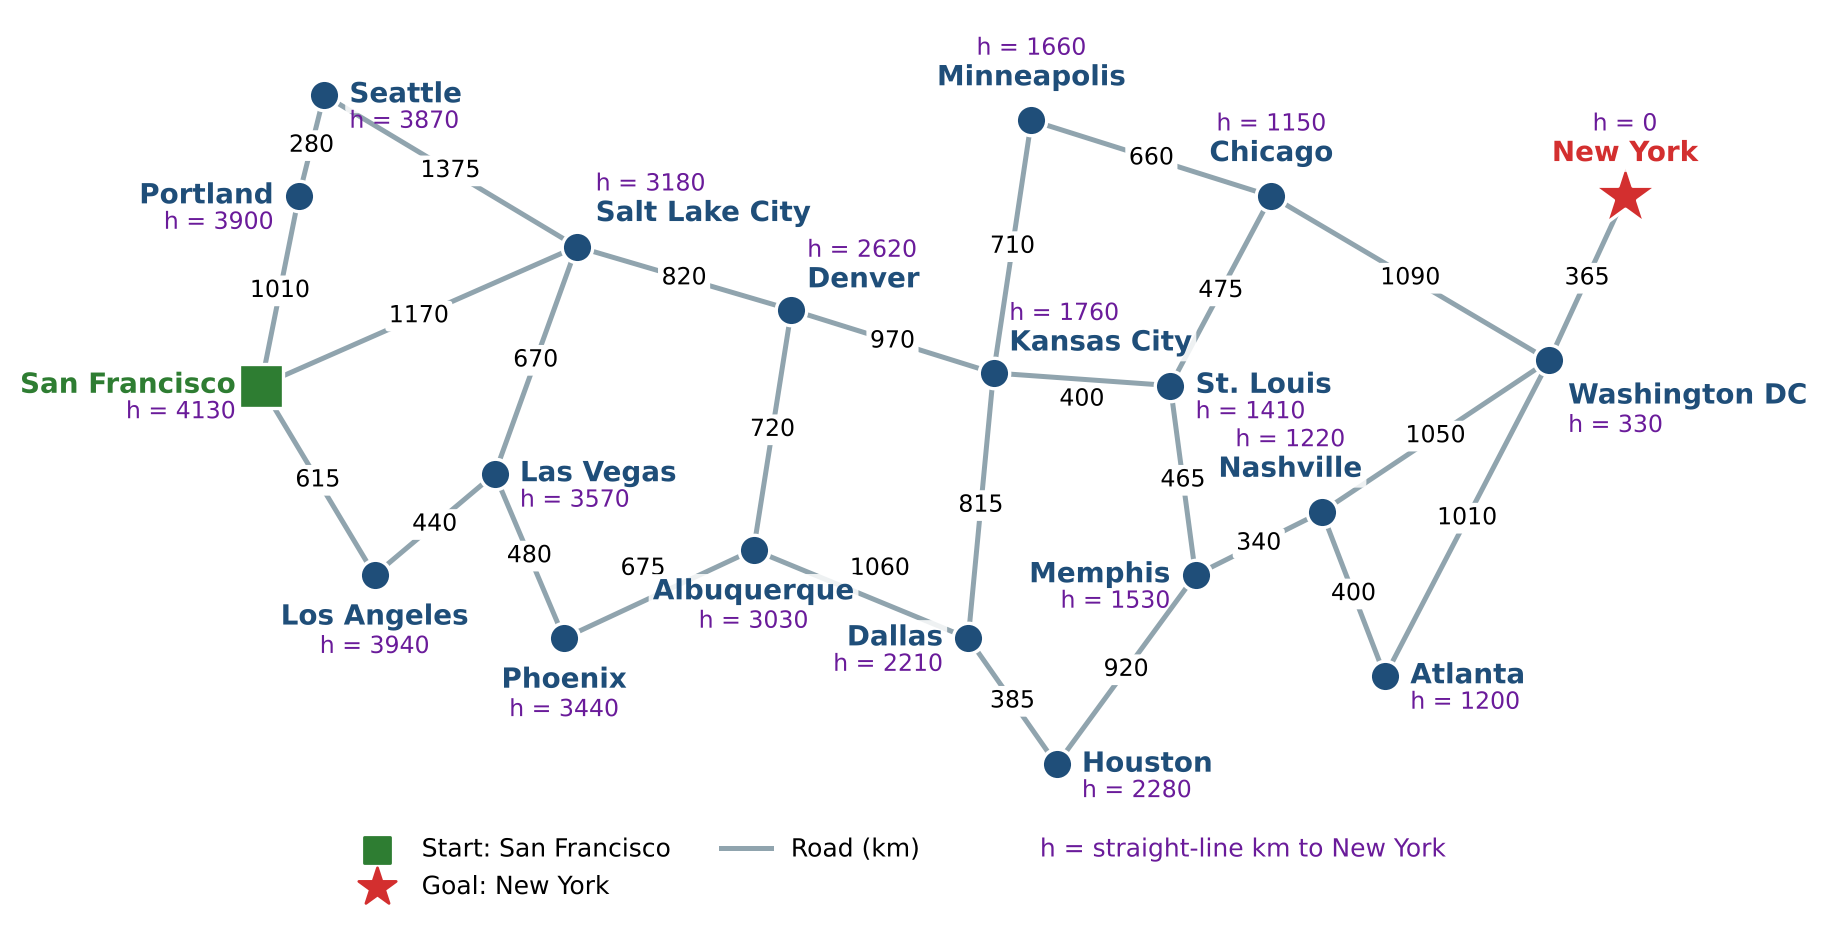



**Network Table**
| Road | Distance (km) | Town | h(n): straight-line distance (km) to New York |
| :--- | :---: | :--- | :---: |
| San Francisco – Portland | 1010 | San Francisco | 4130 |
| San Francisco – Los Angeles | 615 | Los Angeles | 3940 |
| San Francisco – Salt Lake City | 1170 | Portland | 3900 |
| Seattle – Portland | 280 | Seattle | 3870 |
| Seattle – Salt Lake City | 1375 | Las Vegas | 3570 |
| Los Angeles – Las Vegas | 440 | Phoenix | 3440 |
| Las Vegas – Salt Lake City | 670 | Salt Lake City | 3180 |
| Las Vegas – Phoenix | 480 | Albuquerque | 3030 |
| Phoenix – Albuquerque | 675 | Denver | 2620 |
| Salt Lake City – Denver | 820 | Houston | 2280 |
| Albuquerque – Denver | 720 | Dallas | 2210 |
| Albuquerque – Dallas | 1060 | Kansas City | 1760 |
| Denver – Kansas City | 970 | Minneapolis | 1660 |
| Dallas – Houston | 385 | Memphis | 1530 |
| Dallas – Kansas City | 815 | St. Louis | 1410 |
| Houston – Memphis | 920 | Nashville | 1220 |
| Kansas City – St. Louis | 400 | Atlanta | 1200 |
| Kansas City – Minneapolis | 710 | Chicago | 1150 |
| Minneapolis – Chicago | 660 | Washington DC | 330 |
| St. Louis – Chicago | 475 | New York | 0 |
| St. Louis – Memphis | 465 | | |
| Memphis – Nashville | 340 | | |
| Nashville – Atlanta | 400 | | |
| Nashville – Washington DC | 1050 | | |
| Atlanta – Washington DC | 1010 | | |
| Chicago – Washington DC | 1090 | | |
| Washington DC – New York | 365 | | |




### Exercise 15:
**Task 1:** By hand (manual calculations) determine the route from San Francisco to New York using the following Search Algorithms:
i. BFS
ii. DFS
iii. UCS

**Solution:**

Using `GraphProblem` from the codebase (`actions(state)` returns `sorted(self.nbrs[state])` in alphabetical order):

| City | Adjacency List (Connected Cities, alphabetical) |
| :--- | :--- |
| San Francisco | Los Angeles, Portland, Salt Lake City |
| Los Angeles | Las Vegas, San Francisco |
| Portland | San Francisco, Seattle |
| Seattle | Portland, Salt Lake City |
| Las Vegas | Los Angeles, Phoenix, Salt Lake City |
| Phoenix | Albuquerque, Las Vegas |
| Salt Lake City | Denver, Las Vegas, San Francisco, Seattle |
| Albuquerque | Dallas, Denver, Phoenix |
| Denver | Albuquerque, Kansas City, Salt Lake City |
| Houston | Dallas, Memphis |
| Dallas | Albuquerque, Houston, Kansas City |
| Kansas City | Dallas, Denver, Minneapolis, St. Louis |
| Minneapolis | Chicago, Kansas City |
| Memphis | Houston, Nashville, St. Louis |
| St. Louis | Chicago, Kansas City, Memphis |
| Nashville | Atlanta, Memphis, Washington DC |
| Atlanta | Nashville, Washington DC |
| Chicago | Minneapolis, St. Louis, Washington DC |
| Washington DC | Atlanta, Chicago, Nashville, New York |
| New York | (GOAL) |

---

**i. BFS** (`breadth_first_search`: FIFO `deque`, `reached` set, early goal test on child generation, neighbors in alphabetical order)

* **Level 0:** Expand `San Francisco` -> generates `Los Angeles` (d=1), `Portland` (d=1), `Salt Lake City` (d=1).
* **Level 1:** Expand `Los Angeles` -> `Las Vegas` (d=2); Expand `Portland` -> `Seattle` (d=2); Expand `Salt Lake City` -> `Denver` (d=2).
* **Level 2:** Expand `Las Vegas` -> `Phoenix` (d=3); Expand `Seattle` -> (all neighbors reached); Expand `Denver` -> `Albuquerque` (d=3), `Kansas City` (d=3).
* **Level 3:** Expand `Phoenix` -> (all neighbors reached); Expand `Albuquerque` -> `Dallas` (d=4); Expand `Kansas City` -> `Minneapolis` (d=4), `St. Louis` (d=4).
* **Level 4:** Expand `Dallas` -> `Houston` (d=5); Expand `Minneapolis` -> `Chicago` (d=5); Expand `St. Louis` -> `Memphis` (d=5).
* **Level 5:** Expand `Houston` -> (all neighbors reached); Expand `Chicago` -> `Washington DC` (d=6); Expand `Memphis` -> `Nashville` (d=6).
* **Level 6:** Expand `Washington DC` -> generates `Atlanta` (d=7), `New York` (d=7, **GOAL** — early goal test returns immediately!).
* **BFS Route:** `San Francisco -> Salt Lake City -> Denver -> Kansas City -> Minneapolis -> Chicago -> Washington DC -> New York`
* **Steps:** 7 | **Total Cost:** $1170 + 820 + 970 + 710 + 660 + 1090 + 365 = \mathbf{5785	ext{ km}}$ (17 nodes expanded).

---

**ii. DFS** (`depth_first_search`: LIFO stack `frontier.pop()`, `reached` set, goal test on pop; pushing neighbors in alphabetical order means the **last** alphabetical neighbor is popped first)

* Pop `San Francisco` -> push `Los Angeles`, `Portland`, `Salt Lake City`.
* Pop `Salt Lake City` -> push `Denver`, `Las Vegas`, `Seattle`.
  * Pop `Seattle` -> push `Portland`; Pop `Portland` -> no unreached neighbors (backtrack).
  * Pop `Las Vegas` -> push `Phoenix`.
  * Pop `Phoenix` -> push `Albuquerque`.
  * Pop `Albuquerque` -> push `Dallas` (`Denver` is already in `reached`).
  * Pop `Dallas` -> push `Houston`, `Kansas City`.
  * Pop `Kansas City` -> push `Minneapolis`, `St. Louis`.
  * Pop `St. Louis` -> push `Chicago`, `Memphis`.
  * Pop `Memphis` -> push `Nashville`.
  * Pop `Nashville` -> push `Atlanta`, `Washington DC`.
  * Pop `Washington DC` -> push `New York`.
  * Pop `New York` -> **GOAL!**
* **DFS Route:** `San Francisco -> Salt Lake City -> Las Vegas -> Phoenix -> Albuquerque -> Dallas -> Kansas City -> St. Louis -> Memphis -> Nashville -> Washington DC -> New York`
* **Steps:** 11 | **Total Cost:** $1170 + 670 + 480 + 675 + 1060 + 815 + 400 + 465 + 340 + 1050 + 365 = \mathbf{7490	ext{ km}}$ (12 nodes expanded).

---

**iii. UCS** (`uniform_cost_search`: priority queue ordered by $g(n)$, `reached` dict storing cheapest node, goal test on pop)

* Expands nodes in increasing order of $g(n)$:
  1. `San Francisco` ($g=0$)
  2. `Los Angeles` ($g=615$)
  3. `Portland` ($g=1010$)
  4. `Las Vegas` ($g=1055$, via LA)
  5. `Salt Lake City` ($g=1170$)
  6. `Seattle` ($g=1290$, via Portland)
  7. `Phoenix` ($g=1535$, via Las Vegas)
  8. `Denver` ($g=1990$, via Salt Lake City)
  9. `Albuquerque` ($g=2210$, via Phoenix)
  10. `Kansas City` ($g=2960$, via Denver)
  11. `Dallas` ($g=3270$, via Albuquerque)
  12. `St. Louis` ($g=3360$, via Kansas City)
  13. `Houston` ($g=3655$, via Dallas)
  14. `Minneapolis` ($g=3670$, via Kansas City)
  15. `Memphis` ($g=3825$, via St. Louis)
  16. `Chicago` ($g=3835$, via St. Louis)
  17. `Nashville` ($g=4165$, via Memphis)
  18. `Atlanta` ($g=4565$, via Nashville)
  19. `Washington DC` ($g=4925$, via Chicago; cheaper than via Nashville's $5215$)
  20. Pop `New York` ($g=5290$, **GOAL**)
* **UCS Route:** `San Francisco -> Salt Lake City -> Denver -> Kansas City -> St. Louis -> Chicago -> Washington DC -> New York`
* **Steps:** 7 | **Total Cost:** $1170 + 820 + 970 + 400 + 475 + 1090 + 365 = \mathbf{5290	ext{ km}}$ (19 nodes expanded).

---

**Task 2:** By hand (manual calculations), use A* search to find a route from San Francisco to New York. Show the frontier with the values of g, h and f = g + h after each expansion, give the order in which nodes are expanded, and state the route found and its cost.

**Solution:**

Using `astar_search` (`f(n) = g(n) + h(n)`), popping the minimum-$f$ node from the frontier (note: stale entries in the heap from earlier, higher-cost paths to a state are skipped when popped):

1. **Expand `San Francisco`** ($g=0, h=4130, f=4130$)  
   * Frontier: `Salt Lake City(g=1170, h=3180, f=4350)`, `Los Angeles(g=615, h=3940, f=4555)`, `Portland(g=1010, h=3900, f=4910)`
2. **Expand `Salt Lake City`** ($g=1170, h=3180, f=4350$)  
   * Frontier: `Los Angeles(g=615, h=3940, f=4555)`, `Denver(g=1990, h=2620, f=4610)`, `Portland(g=1010, h=3900, f=4910)`, `Las Vegas(g=1840, h=3570, f=5410)`, `Seattle(g=2545, h=3870, f=6415)`
3. **Expand `Los Angeles`** ($g=615, h=3940, f=4555$)  
   * Frontier: `Denver(g=1990, h=2620, f=4610)`, `Las Vegas(g=1055, h=3570, f=4625)`, `Portland(g=1010, h=3900, f=4910)`, `Seattle(g=2545, h=3870, f=6415)` *(plus stale Las Vegas f=5410)*
4. **Expand `Denver`** ($g=1990, h=2620, f=4610$)  
   * Frontier: `Las Vegas(g=1055, h=3570, f=4625)`, `Kansas City(g=2960, h=1760, f=4720)`, `Portland(g=1010, h=3900, f=4910)`, `Albuquerque(g=2710, h=3030, f=5740)`, `Seattle(g=2545, h=3870, f=6415)`
5. **Expand `Las Vegas`** ($g=1055, h=3570, f=4625$)  
   * Frontier: `Kansas City(g=2960, h=1760, f=4720)`, `Portland(g=1010, h=3900, f=4910)`, `Phoenix(g=1535, h=3440, f=4975)`, `Albuquerque(g=2710, h=3030, f=5740)`, `Seattle(g=2545, h=3870, f=6415)`
6. **Expand `Kansas City`** ($g=2960, h=1760, f=4720$)  
   * Frontier: `St. Louis(g=3360, h=1410, f=4770)`, `Portland(g=1010, h=3900, f=4910)`, `Phoenix(g=1535, h=3440, f=4975)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Albuquerque(g=2710, h=3030, f=5740)`, `Dallas(g=3775, h=2210, f=5985)`, `Seattle(g=2545, h=3870, f=6415)`
7. **Expand `St. Louis`** ($g=3360, h=1410, f=4770$)  
   * Frontier: `Portland(g=1010, h=3900, f=4910)`, `Phoenix(g=1535, h=3440, f=4975)`, `Chicago(g=3835, h=1150, f=4985)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Albuquerque(g=2710, h=3030, f=5740)`, `Dallas(g=3775, h=2210, f=5985)`, `Seattle(g=2545, h=3870, f=6415)`
8. **Expand `Portland`** ($g=1010, h=3900, f=4910$)  
   * Frontier: `Phoenix(g=1535, h=3440, f=4975)`, `Chicago(g=3835, h=1150, f=4985)`, `Seattle(g=1290, h=3870, f=5160)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Albuquerque(g=2710, h=3030, f=5740)`, `Dallas(g=3775, h=2210, f=5985)`
9. **Expand `Phoenix`** ($g=1535, h=3440, f=4975$)  
   * Frontier: `Chicago(g=3835, h=1150, f=4985)`, `Seattle(g=1290, h=3870, f=5160)`, `Albuquerque(g=2210, h=3030, f=5240)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Dallas(g=3775, h=2210, f=5985)`
10. **Expand `Chicago`** ($g=3835, h=1150, f=4985$)  
    * Frontier: `Seattle(g=1290, h=3870, f=5160)`, `Albuquerque(g=2210, h=3030, f=5240)`, `Washington DC(g=4925, h=330, f=5255)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Dallas(g=3775, h=2210, f=5985)`
11. **Expand `Seattle`** ($g=1290, h=3870, f=5160$)  
    * Frontier: `Albuquerque(g=2210, h=3030, f=5240)`, `Washington DC(g=4925, h=330, f=5255)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Dallas(g=3775, h=2210, f=5985)`
12. **Expand `Albuquerque`** ($g=2210, h=3030, f=5240$)  
    * Frontier: `Washington DC(g=4925, h=330, f=5255)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Dallas(g=3270, h=2210, f=5480)`
13. **Expand `Washington DC`** ($g=4925, h=330, f=5255$)  
    * Frontier: `New York(g=5290, h=0, f=5290)`, `Minneapolis(g=3670, h=1660, f=5330)`, `Memphis(g=3825, h=1530, f=5355)`, `Dallas(g=3270, h=2210, f=5480)`, `Atlanta(g=5935, h=1200, f=7135)`, `Nashville(g=5975, h=1220, f=7195)`
14. **Pop `New York`** ($g=5290, h=0, f=5290$) -> **GOAL!**

* **Order of node expansions (popped):**  
  `San Francisco -> Salt Lake City -> Los Angeles -> Denver -> Las Vegas -> Kansas City -> St. Louis -> Portland -> Phoenix -> Chicago -> Seattle -> Albuquerque -> Washington DC -> New York (GOAL)` (13 expansions before popping the goal).
* **Route found:**  
  `San Francisco -> Salt Lake City -> Denver -> Kansas City -> St. Louis -> Chicago -> Washington DC -> New York`
* **Total cost:** **5290 km**


## Before you submit

1. Run **Kernel → Restart & Run All** and check that every test cell prints its success message.
2. Make sure Exercises 5, 8, 11, 14 and 15 have written answers.
